# Data Processing

## Import packages
Dependency Specification: pandas==3.0.5, duckdb==1.5.6

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from utils import *

## Load Data

Load data and select features with an SQL query through the duckdb.

Based on the EDA results, `year`, `patch`, and `gamelength` are removed because they have 0.00 correlation with the target variable `result`.
On the other hand, `towers`, `assists`, `assistsatX`, `goldspent`, `opp_deathsatX`, `golddiffat20`, and `xpdiffat20` are removed because they have high correlation with other variables, which may cause multicollinearity during modeling. This also applies to stats at the 25th minute mark as they correlate high with the stats at the 20th minute mark.

In [2]:
# Adjust list based on the features considered
cols_to_include = ['gameid', 'league', 'split', 'date', 'teamname',
                   'result', 'kills', 'deaths', 'dpm', 
                   'damagetakenperminute', 'wardskilled', 'totalgold',
                   'firstdragon', 'firstbaron', 'barons', 'opp_barons',
                   'golddiffat10', 'xpdiffat10', 'killsat10', 'opp_killsat10',
                   'golddiffat15', 'xpdiffat15', 'killsat15', 'opp_killsat15',
                   'killsat20', 'opp_killsat20'
                   ]

db = 'lol_predictors.duckdb'
df_selected = "df_2026" # temporarily hardcoded df name
df = data_selection(df_selected, cols_to_include, db)

## Data Cleaning

For **data imputation**, only the feature `split` has missing values based on df_2014's EDA. We can use the previous value for each NaN since there's only two values, which are `Summer` and `Spring`, and they are sorted chronologically.

In [3]:
df['split'] = df['split'].ffill()

We will **trim outliers** because even the feature `wardskilled` that has the highest outlier percentage only has `<2%` of outliers.

In [4]:
num_cols = df.select_dtypes(include=["number"]).columns.tolist()

print(num_cols)

for col in num_cols:
    df = df[~detect_outliers(df, col).to_numpy()]

['result', 'kills', 'deaths', 'dpm', 'damagetakenperminute', 'wardskilled', 'totalgold', 'firstdragon', 'firstbaron', 'barons', 'opp_barons', 'golddiffat10', 'xpdiffat10', 'killsat10', 'opp_killsat10', 'golddiffat15', 'xpdiffat15', 'killsat15', 'opp_killsat15', 'killsat20', 'opp_killsat20']


This concludes data cleaning of df_2014, which is the Lol Esports data on 2014 based on Oracle's Elixir. From the EDA, there are no categories in categorical features that needs fixing. 

## Post-Processing Data Audit

In [5]:
df.info()

<class 'pandas.DataFrame'>
Index: 16712 entries, 0 to 19505
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   gameid                16712 non-null  str    
 1   league                16712 non-null  str    
 2   split                 16712 non-null  str    
 3   date                  16712 non-null  str    
 4   teamname              16712 non-null  str    
 5   result                16712 non-null  int64  
 6   kills                 16712 non-null  int64  
 7   deaths                16712 non-null  int64  
 8   dpm                   16712 non-null  float64
 9   damagetakenperminute  16712 non-null  float64
 10  wardskilled           16712 non-null  int64  
 11  totalgold             16712 non-null  int64  
 12  firstdragon           16694 non-null  float64
 13  firstbaron            16269 non-null  float64
 14  barons                16712 non-null  float64
 15  opp_barons            16712 non-nul

In [6]:
df.shape

(16712, 26)

In [7]:
display(df.describe())

,result,kills,deaths,dpm,damagetakenperminute,wardskilled,totalgold,firstdragon,firstbaron,barons,...,golddiffat10,xpdiffat10,killsat10,opp_killsat10,golddiffat15,xpdiffat15,killsat15,opp_killsat15,killsat20,opp_killsat20
count,16712.000000,16712.000000,16712.000000,16712.000000,16712.000000,16712.000000,16712.000000,16694.000000,16269.000000,16712.000000,...,16379.000000,16379.000000,16379.000000,16379.000000,16381.000000,16381.000000,16381.000000,16381.000000,16378.000000,16378.000000
mean,0.497188,15.896601,15.970919,2835.103219,3674.298330,43.449438,61237.068992,0.499221,0.484541,0.659885,...,-2.811527,-1.768362,2.382258,2.386226,-5.660949,-3.810146,4.616873,4.623039,7.305715,7.313775
std,0.500007,7.616941,7.634537,631.701045,599.319354,14.829196,10616.995326,0.500014,0.499776,0.685592,...,1335.477463,995.911408,1.797165,1.799152,2593.776183,2159.160717,2.744464,2.744995,3.912069,3.913257
min,0.000000,0.000000,0.000000,1056.632700,2021.787000,6.000000,30524.000000,0.000000,0.000000,0.000000,...,-3969.000000,-2823.000000,0.000000,0.000000,-7350.000000,-6021.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,10.000000,10.000000,2383.835250,3253.431300,32.000000,53942.750000,0.000000,0.000000,0.000000,...,-919.000000,-672.500000,1.000000,1.000000,-1748.000000,-1466.000000,3.000000,3.000000,4.000000,4.000000
50%,0.000000,16.000000,16.000000,2819.836150,3651.920250,42.000000,61249.000000,0.000000,0.000000,1.000000,...,-1.000000,-4.000000,2.000000,2.000000,-9.000000,-5.000000,4.000000,4.000000,7.000000,7.000000
75%,1.000000,22.000000,22.000000,3267.066700,4080.017375,53.000000,68484.250000,1.000000,1.000000,1.000000,...,912.000000,670.500000,3.000000,3.000000,1741.000000,1458.000000,6.000000,6.000000,10.000000,10.000000
max,1.000000,40.000000,40.000000,4713.881200,5390.724900,86.000000,91347.000000,1.000000,1.000000,2.000000,...,3969.000000,2823.000000,8.000000,8.000000,7346.000000,6007.000000,13.000000,13.000000,19.000000,19.000000


In [8]:
data_profiling(df)

List of Columns: Index(['gameid', 'league', 'split', 'teamname', 'result', 'kills', 'deaths',
       'dpm', 'damagetakenperminute', 'wardskilled', 'totalgold',
       'firstdragon', 'firstbaron', 'barons', 'opp_barons', 'golddiffat10',
       'xpdiffat10', 'killsat10', 'opp_killsat10', 'golddiffat15',
       'xpdiffat15', 'killsat15', 'opp_killsat15', 'killsat20',
       'opp_killsat20'],
      dtype='str')

------------ COUNT OF MISSING VALUES -------------


gameid                    0
league                    0
split                     0
teamname                  0
result                    0
kills                     0
deaths                    0
dpm                       0
damagetakenperminute      0
wardskilled               0
totalgold                 0
firstdragon              18
firstbaron              443
barons                    0
opp_barons                0
golddiffat10            333
xpdiffat10              333
killsat10               333
opp_killsat10           333
golddiffat15            331
xpdiffat15              331
killsat15               331
opp_killsat15           331
killsat20               334
opp_killsat20           334
dtype: int64


------------- COUNT OF UNIQUE VALUES -------------


gameid                   8462
league                     44
split                      17
teamname                  415
result                      2
kills                      41
deaths                     41
dpm                     16697
damagetakenperminute    16703
wardskilled                81
totalgold               13555
firstdragon                 2
firstbaron                  2
barons                      3
opp_barons                  3
golddiffat10             5312
xpdiffat10               4277
killsat10                   9
opp_killsat10               9
golddiffat15             8120
xpdiffat15               7375
killsat15                  14
opp_killsat15              14
killsat20                  20
opp_killsat20              20
dtype: int64


--------- UNIQUE VALUES OF OBJECT SERIES ---------

 league
LPL          1243
EM            906
LCK           905
LCKC          904
LAS           790
LEC           697
LJL           587
PRM           576
AL            575
CBLOL         556
LCS           521
LCP           503
NACL          499
LIT           488
LFL           487
CD            451
EWC           421
ROL           405
RL            377
TCL           376
HLL           362
LES           358
NLC           330
HC            326
LRS           324
EBL           318
LRN           290
NL            262
VCS           252
LPLOL         241
HM            211
HW            154
PCS           146
WSCI          145
DCGI          136
MSI           124
KeSPA Cup     111
AM             89
FST            83
CCWS           67
WLDs           65
AC             33
WLRQ           12
DCup            6
Name: count, dtype: int64

 split
Summer        3865
Spring        3639
Winter        1980
Split 2       1490
Split 1       1297
Rounds 1-2     918

In [9]:
# Limit numerical columns for description and visualization
numcols_to_drop = ['result', 'firstbaron', 'firstdragon']

# Limit categorical columns for description and visualization
catcols_to_drop = ['gameid', 'teamname']

In [10]:
count_outliers(df, numcols_to_drop)


--------------- COUNT OF OUTLIERS ----------------
kills:                      0 (0.00%)
deaths:                     0 (0.00%)
dpm:                       23 (0.14%)
damagetakenperminute:      37 (0.22%)
wardskilled:               43 (0.26%)
totalgold:                 23 (0.14%)
barons:                     0 (0.00%)
opp_barons:                 0 (0.00%)
golddiffat10:              53 (0.32%)
xpdiffat10:                60 (0.36%)
killsat10:                421 (2.52%)
opp_killsat10:            425 (2.54%)
golddiffat15:              32 (0.19%)
xpdiffat15:                30 (0.18%)
killsat15:                478 (2.86%)
opp_killsat15:            482 (2.88%)
killsat20:                  0 (0.00%)
opp_killsat20:              0 (0.00%)


*Note that the IQR bounds are dynamically recalculated on each call. These remaining outliers are relative to the newly trimmed distribution. Since the new percentage of outliers is < 1%, it is negligible and safe to retain.*

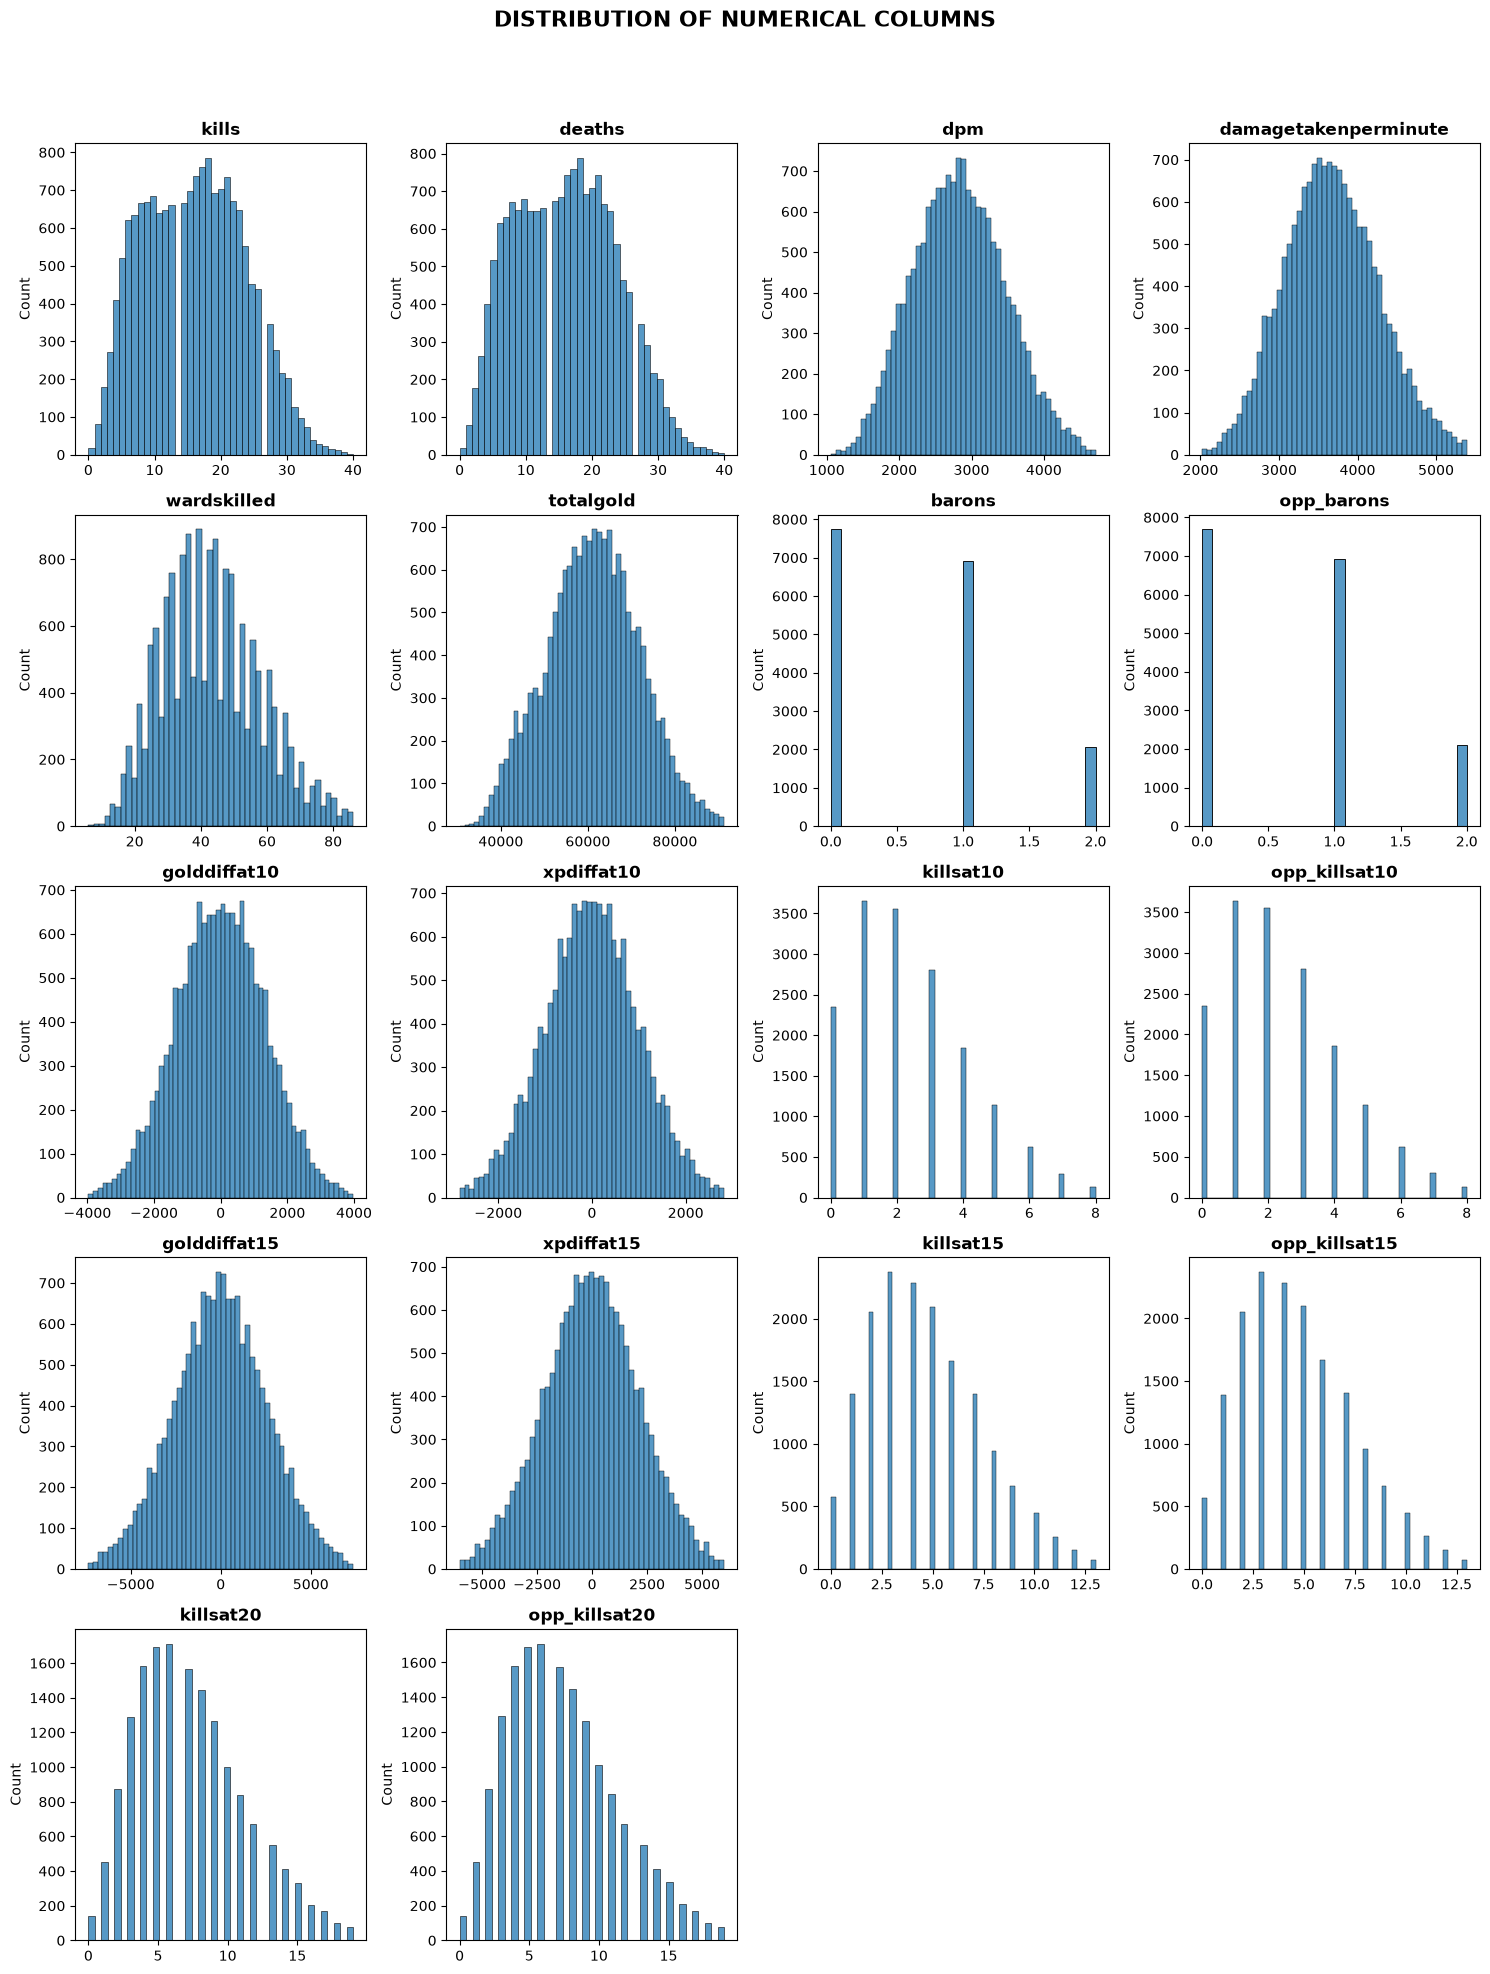

In [11]:
visualize_num_distribution(df, numcols_to_drop, nrows=8, ncols=4, figsize=(15, 30))

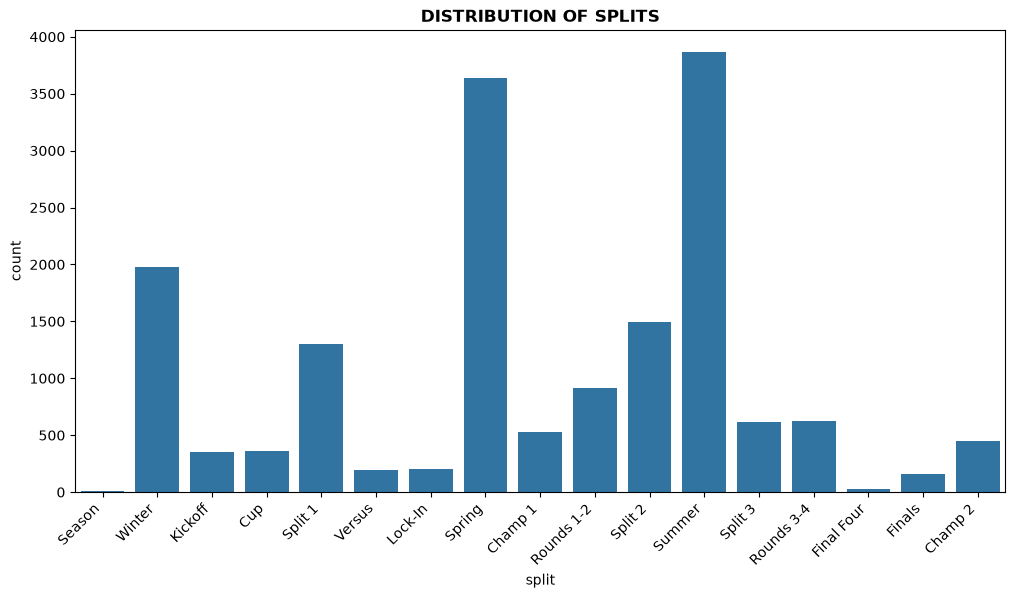

In [16]:
# Visualization of the Splits Distribution
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='split')
plt.title('DISTRIBUTION OF SPLITS', fontsize=12, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.show()

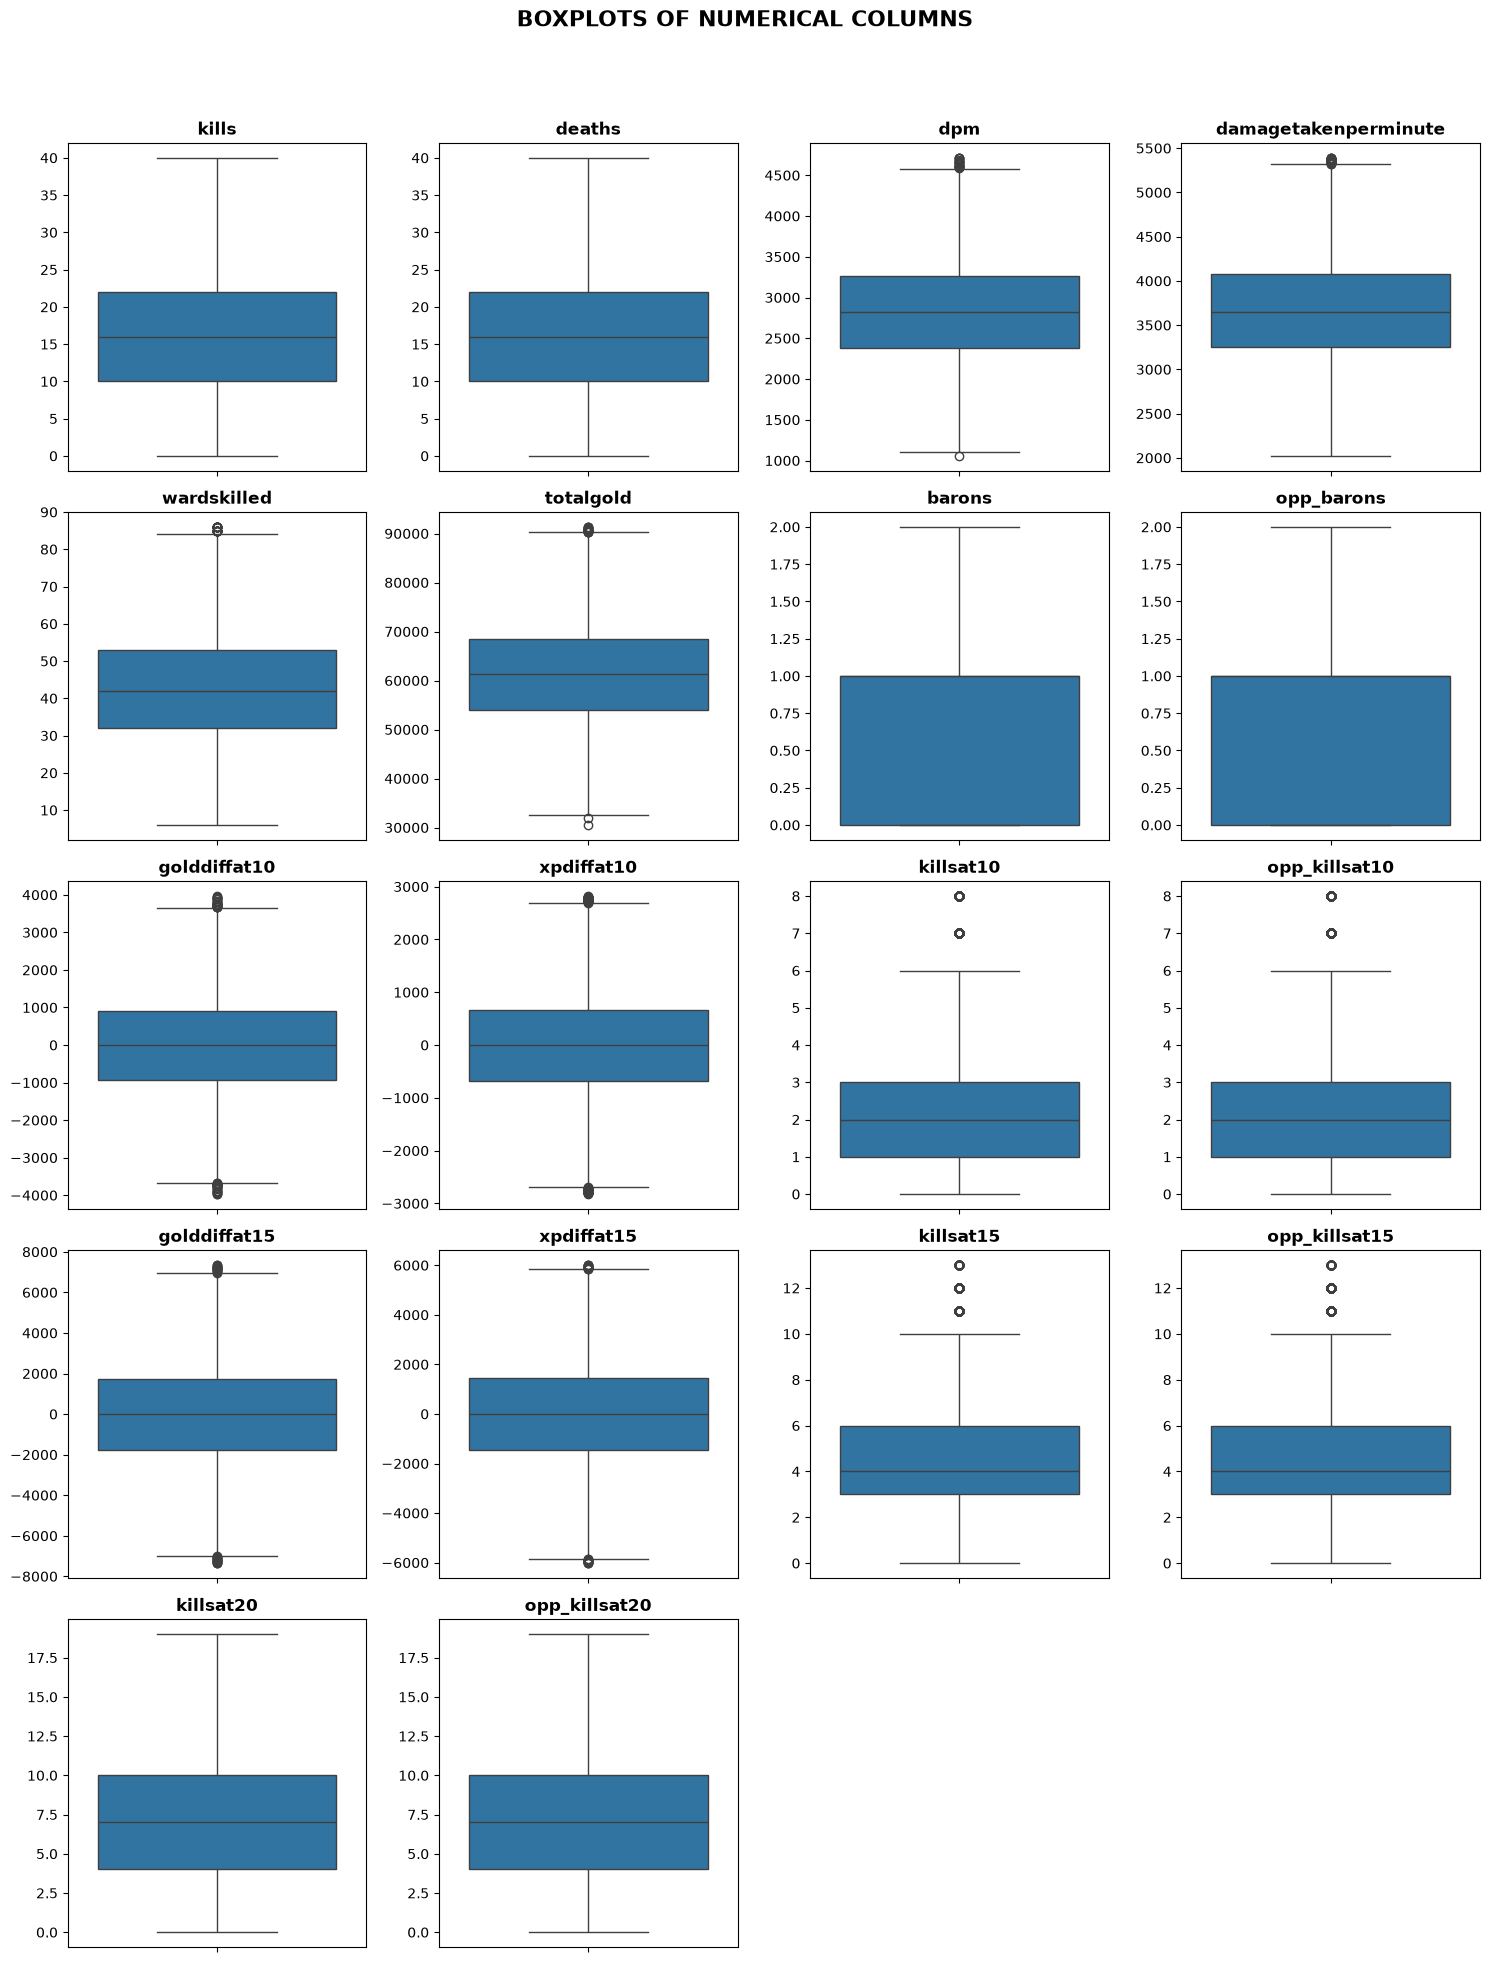

In [13]:
visualize_outliers(df, numcols_to_drop, nrows=8, ncols=4, figsize=(15, 30))

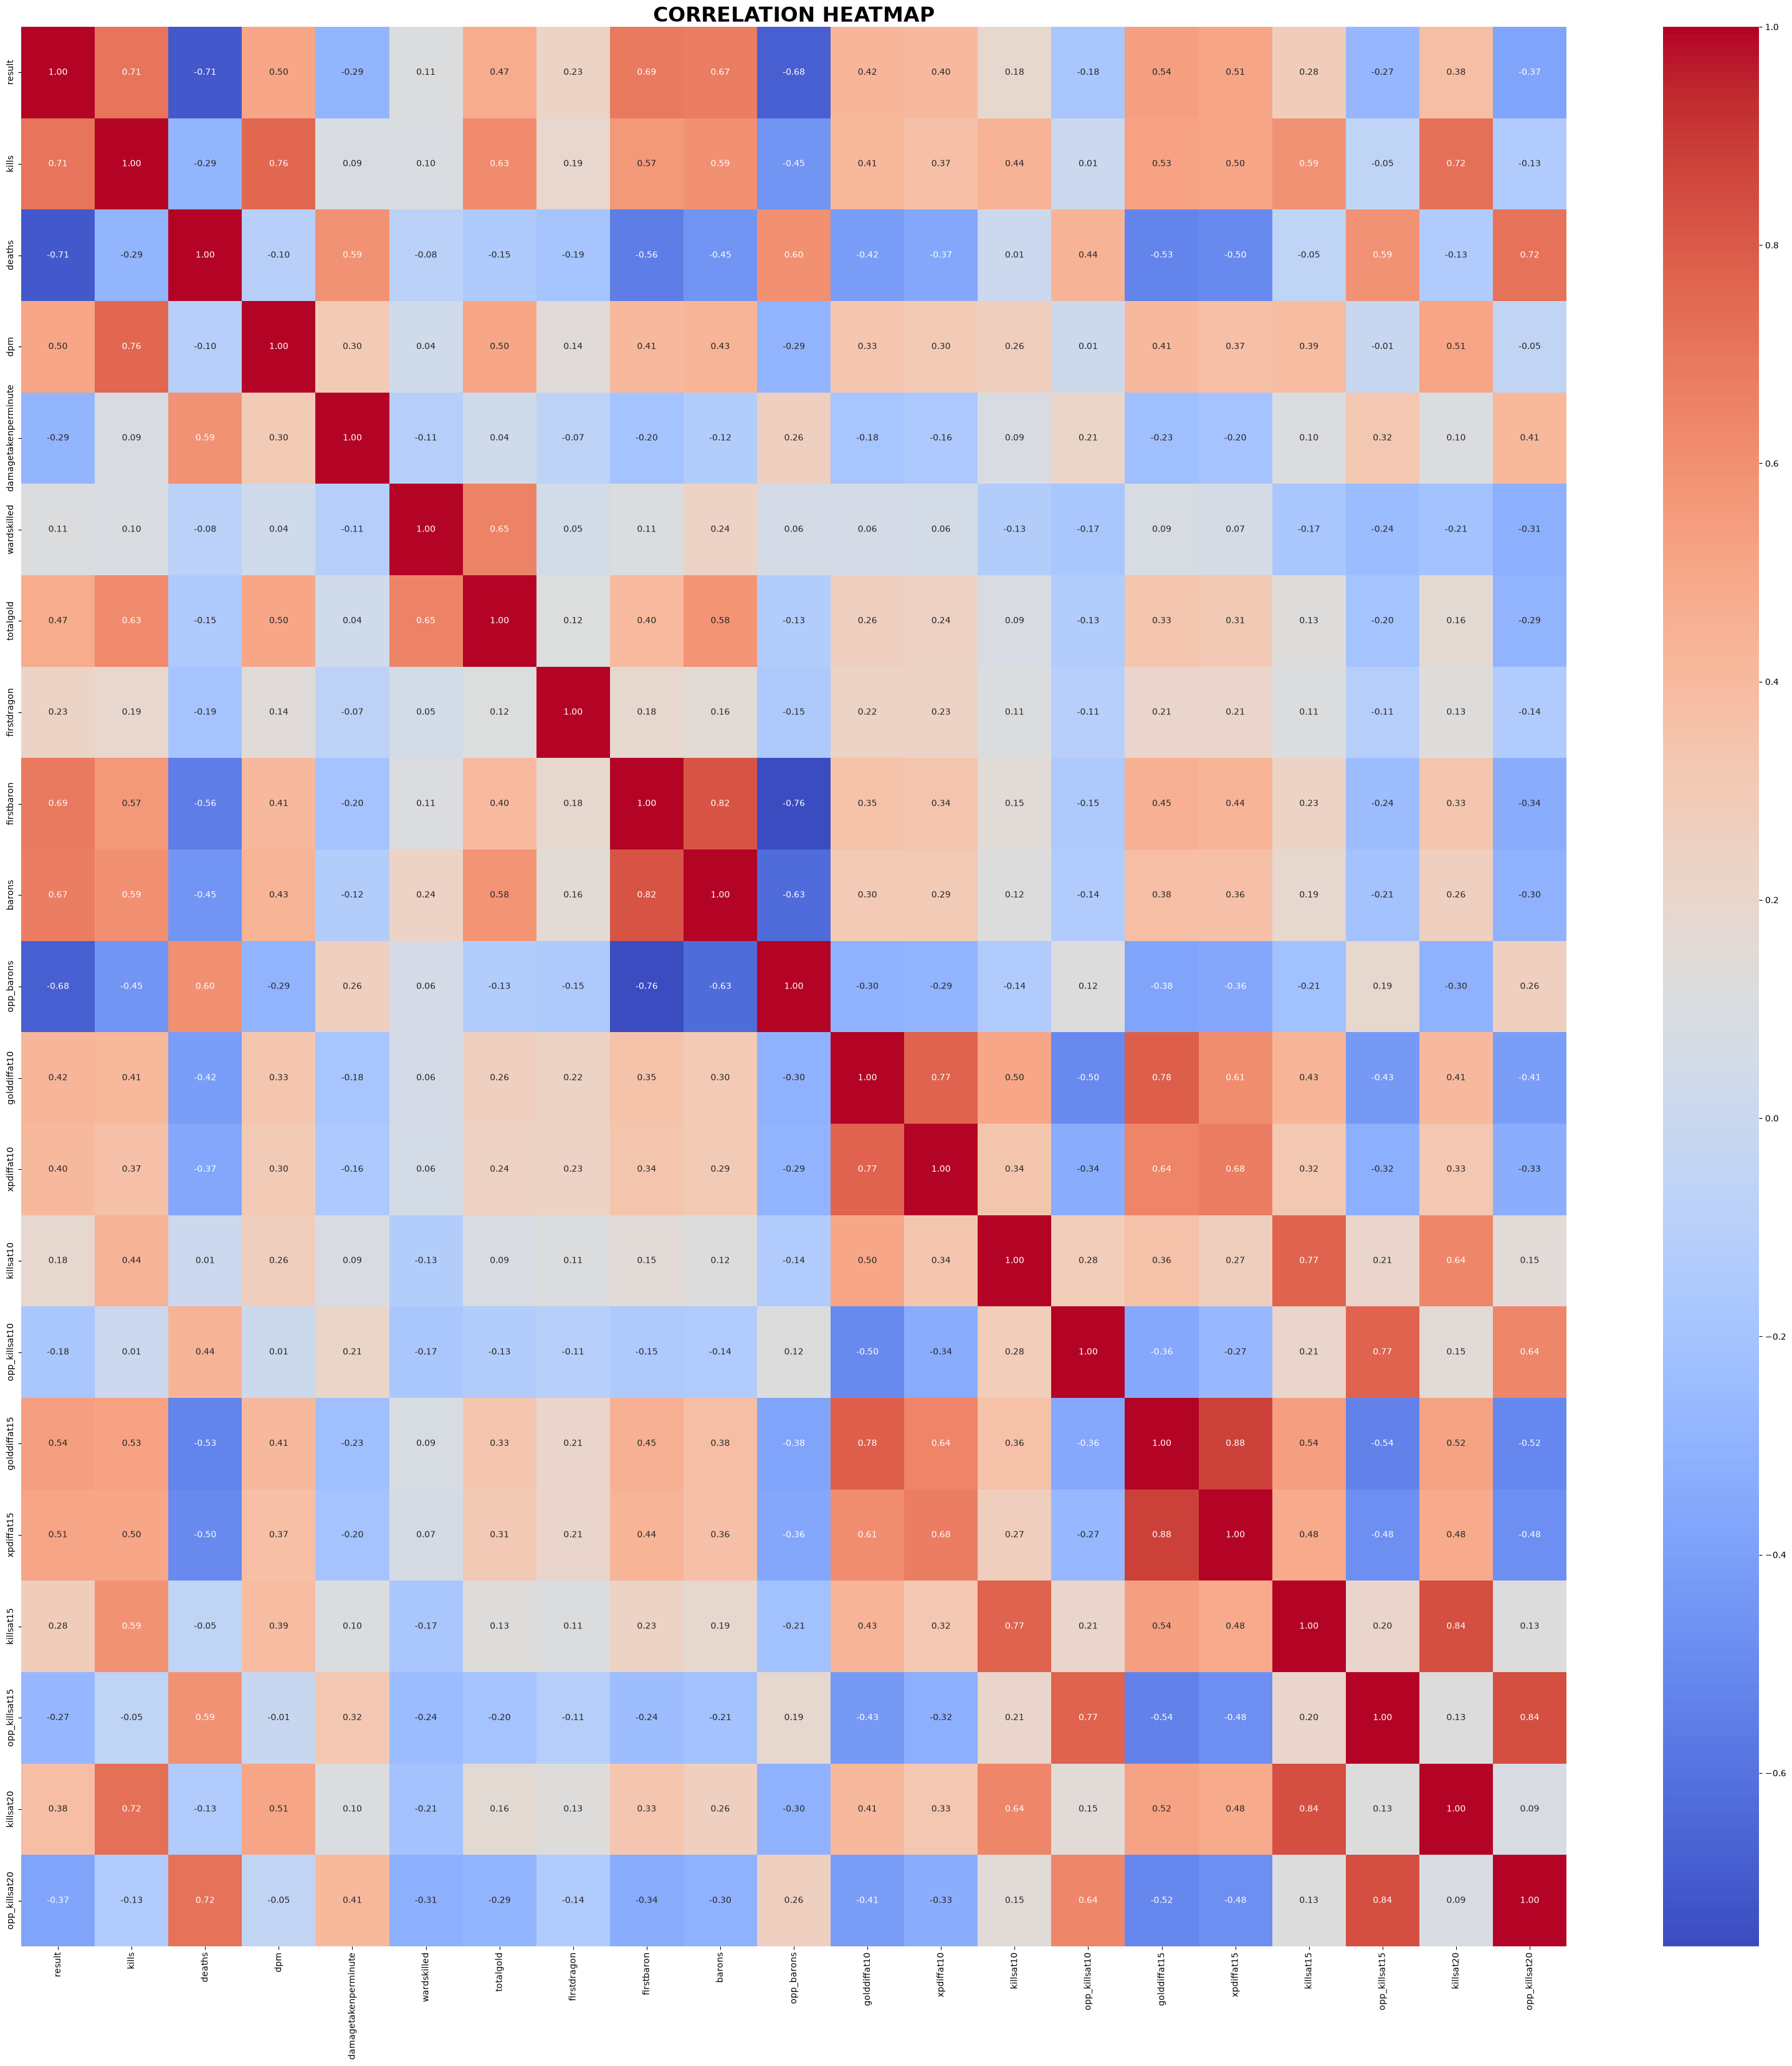

In [14]:
# Compute correlation matrix
co_mtx = df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(40, 40))
sns.heatmap(co_mtx, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('CORRELATION HEATMAP', fontsize=24, fontweight="bold")
plt.show()

In [15]:
df.to_csv("df_processed.csv", index=False)